# Histograma de ASes con mayor grado

In [1]:
import gzip
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

FILE = Path("../paths/bview.rrc00.20250427.0000.gz.txt")
TOP_N = 20

In [2]:
histo = Counter()
print("Counter initialised.")

Counter initialised.


In [3]:
def _open(p: Path):
    with open(p, "rb") as f:
        magic = f.read(2)
    if magic == b"\x1f\x8b":
        return gzip.open(p, "rt")
    return open(p, "rt")

line_count = 0
with _open(FILE) as fh:
    for line in fh:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        # deduplicate ASNs within a path: routing loops or any repeated AS counts once
        for asn in set(line.split()):
            histo[asn] += 1
        line_count += 1
        if line_count % 5_000_000 == 0:
            print(f"  {line_count:,} paths processed…")

print(f"Done — {line_count:,} paths, {len(histo):,} unique ASNs")

  5,000,000 paths processed…
  10,000,000 paths processed…
  15,000,000 paths processed…
  20,000,000 paths processed…
  25,000,000 paths processed…
  30,000,000 paths processed…
  35,000,000 paths processed…
  40,000,000 paths processed…
  45,000,000 paths processed…
  50,000,000 paths processed…
Done — 50,521,713 paths, 84,546 unique ASNs


In [4]:
import httpx
import json
from datetime import datetime, timedelta, timezone

CACHE_PATH = Path.home() / ".cache" / "internet-topology-ris" / "as-names.json"
CACHE_TTL_DAYS = 60

def _load_name_cache():
    if not CACHE_PATH.exists():
        return {}
    try:
        return json.loads(CACHE_PATH.read_text())
    except Exception:
        return {}

def _save_name_cache(cache):
    CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    CACHE_PATH.write_text(json.dumps(cache, indent=2))

def _is_fresh(entry):
    try:
        return datetime.now(timezone.utc) - datetime.fromisoformat(entry["cached_at"]) < timedelta(days=CACHE_TTL_DAYS)
    except Exception:
        return False

def _fetch_name(asn, client):
    url = f"https://stat.ripe.net/data/as-overview/data.json?resource=AS{asn}"
    try:
        r = client.get(url, timeout=15)
        r.raise_for_status()
        body = r.json()
        if body.get("status") != "ok":
            return None
        return body.get("data", {}).get("holder") or None
    except Exception:
        return None

top_asns = [asn for asn, _ in histo.most_common(TOP_N)]
cache = _load_name_cache()

to_fetch = [asn for asn in top_asns if not (str(asn) in cache and _is_fresh(cache[str(asn)]))]
print(f"{len(top_asns) - len(to_fetch)} name(s) from cache, fetching {len(to_fetch)} from RIPEstat…")

with httpx.Client(follow_redirects=True) as client:
    for asn in to_fetch:
        name = _fetch_name(asn, client)
        cache[str(asn)] = {"name": name, "cached_at": datetime.now(timezone.utc).isoformat()}
        print(f"  AS{asn} → {name or '(not found)'}")

if to_fetch:
    _save_name_cache(cache)

names = {asn: (cache.get(str(asn), {}).get("name") or f"AS{asn}") for asn in top_asns}
print(f"\nDone — {len(names)} names ready")

20 name(s) from cache, fetching 0 from RIPEstat…

Done — 20 names ready


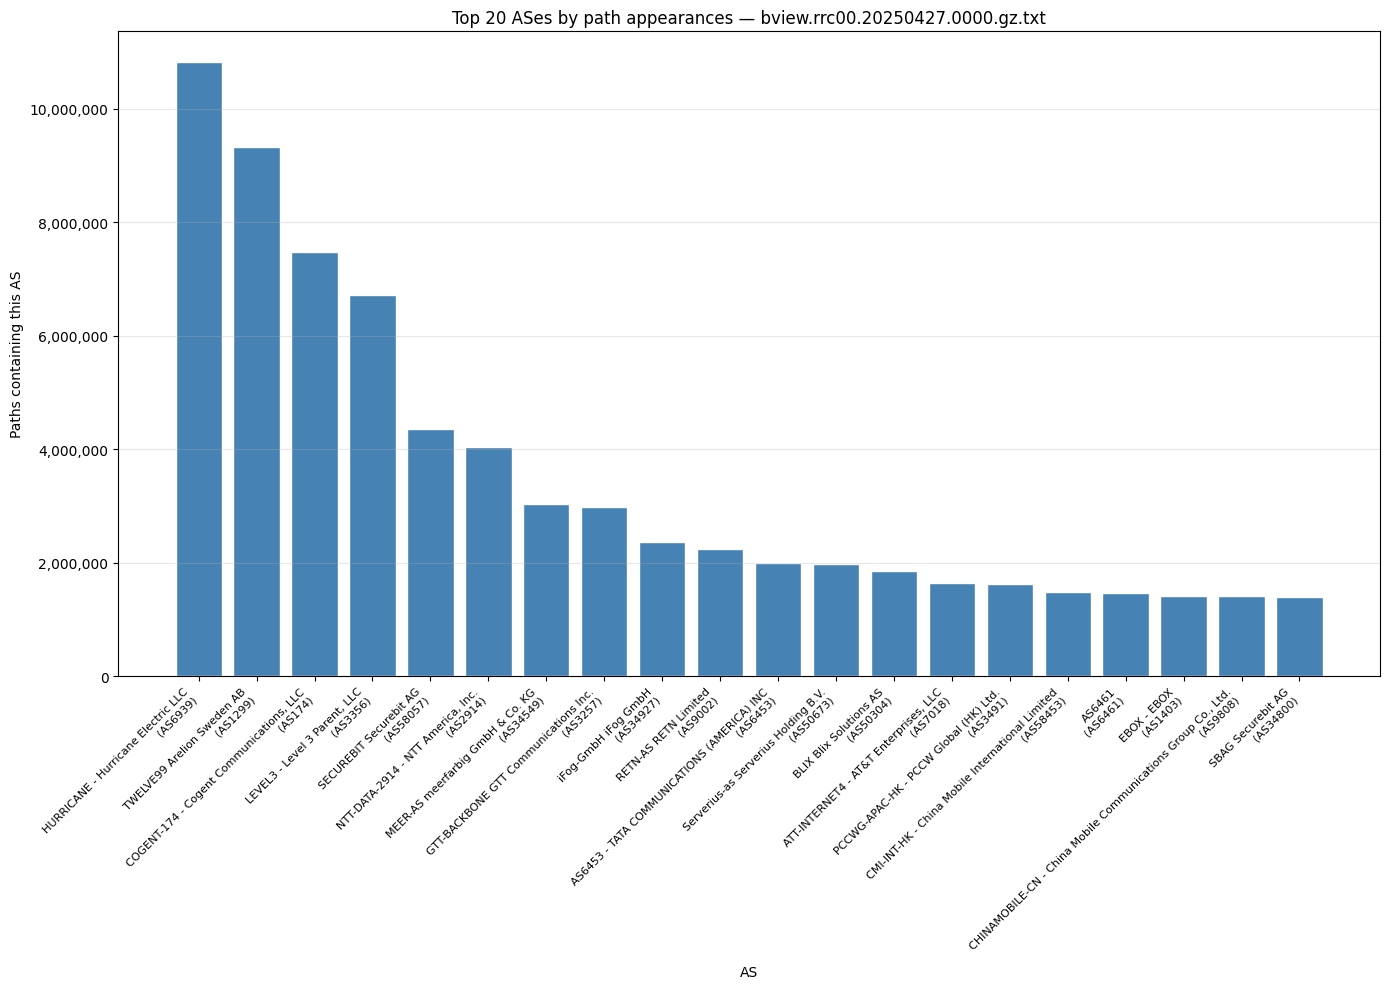

In [5]:
top = histo.most_common(TOP_N)
asns, counts = zip(*top)
labels = [f"{names.get(asn, asn)}\n(AS{asn})" for asn in asns]

fig, ax = plt.subplots(figsize=(14, 10))
ax.bar(range(len(asns)), counts, color="steelblue", edgecolor="white")
ax.set_xticks(range(len(asns)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Paths containing this AS")
ax.set_xlabel("AS")
ax.set_title(f"Top {TOP_N} ASes by path appearances — {FILE.name}")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()